In [1]:
import glob
import numpy as np
import pandas as pd
import os
import re

def average_csv_files_by_language(file_pattern: str, output_directory: str, metadata_file: str, language_column: str):
    # Load the metadata file
    metadata = pd.read_csv(metadata_file)
    
    # Check if the specified language column exists in the metadata
    if language_column not in metadata.columns:
        print(f"Column '{language_column}' not found in metadata file.")
        return
    
    # Split participants into two groups based on language proficiency (0 or 1)
    proficient_participants = metadata[metadata[language_column] == 1]['participant'].astype(str).tolist()
    non_proficient_participants = metadata[metadata[language_column] == 0]['participant'].astype(str).tolist()
    
    # Create directories for the output if they don't exist
    os.makedirs(output_directory, exist_ok=True)
    
    # Helper function to filter files based on participant list and average them
    def average_group_files(participant_list, output_filename):
        group_files = []
        for file in glob.glob(file_pattern):
            match = re.search(r'_(\d+)\.csv$', file)
            if match:
                participant_number = match.group(1)
                if participant_number in participant_list:
                    group_files.append(file)
        
        if not group_files:
            print(f"No files found for participants in group '{output_filename}'.")
            return

        # Initialize a list to hold data frames for averaging
        data_frames = []
        
        # Load each CSV file and add it to the list if the shape matches
        expected_shape = None
        for file in group_files:
            df = pd.read_csv(file)
            
            # Skip files that do not match the shape of the others
            if expected_shape is None:
                expected_shape = df.shape
            elif df.shape != expected_shape:
                print(f"Skipping file {file} due to shape mismatch. Expected {expected_shape}, got {df.shape}.")
                continue

            data_frames.append(df)
        
        if not data_frames:
            print(f"No valid files to average for group '{output_filename}'.")
            return

        # Calculate the mean across all DataFrames
        combined_data = np.mean([df.values for df in data_frames], axis=0)
        
        # Create a DataFrame from the averaged data with the original columns
        avg_df = pd.DataFrame(combined_data, columns=data_frames[0].columns)
        
        # Save the averaged DataFrame to a new CSV file
        avg_df.to_csv(os.path.join(output_directory, output_filename), index=False)
        print(f"Averaged data saved to {output_filename}")

    # Average files for proficient participants
    average_group_files(proficient_participants, f'average_{language_column}_proficient.csv')
    
    # Average files for non-proficient participants
    average_group_files(non_proficient_participants, f'average_{language_column}_non_proficient.csv')

# Define parameters
file_pattern = "/Users/kgmin/Downloads/Individual_ERPs/EEG_Measurements/*_spanish-english_translation_*.csv"
output_directory = '/Users/kgmin/Downloads/Individual_ERPs/Average_English_Spanish_Translation'
metadata_file = '/Users/kgmin/Downloads/Individual_ERPs/metadata.csv'
language_column = 'spanish'  # Example column; adjust as needed

# Execute the function
average_csv_files_by_language(file_pattern, output_directory, metadata_file, language_column)


Averaged data saved to average_spanish_proficient.csv
Averaged data saved to average_spanish_non_proficient.csv


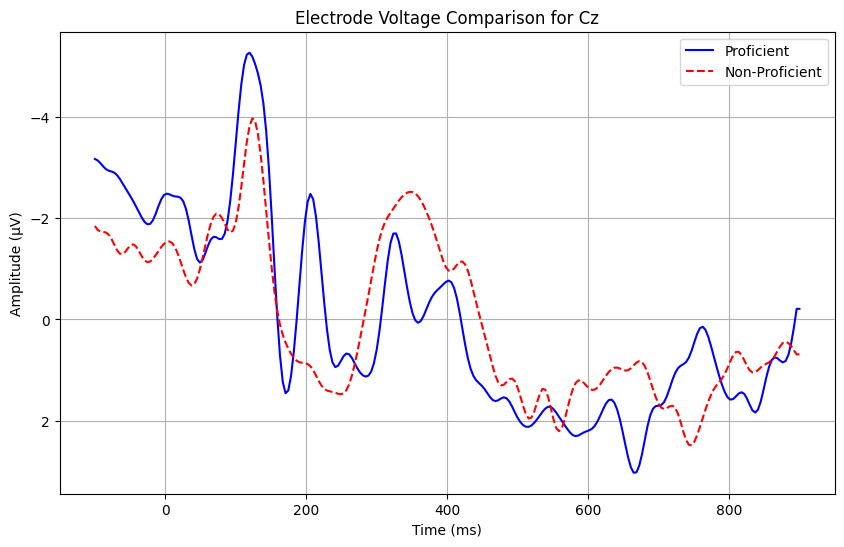

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_electrode_voltage_comparison(proficient_file: str, non_proficient_file: str, electrode_name: str):
    # Load the CSV files
    df_proficient = pd.read_csv(proficient_file)
    df_non_proficient = pd.read_csv(non_proficient_file)
    
    # Check if the specified electrode is in both CSV files
    if electrode_name not in df_proficient.columns or electrode_name not in df_non_proficient.columns:
        print(f"Electrode '{electrode_name}' not found in one or both CSV files.")
        return
    
    # Extract the voltage data for the specified electrode from both groups
    voltage_data_proficient = df_proficient[electrode_name]
    voltage_data_non_proficient = df_non_proficient[electrode_name]
    
    # Generate time points from -100 to 900 ms, evenly spaced based on the number of data points
    time_points = np.linspace(-100, 900, len(voltage_data_proficient))
    
    # Plotting both datasets on the same graph
    plt.figure(figsize=(10, 6))
    
    # Plot for proficient group
    plt.plot(time_points, voltage_data_proficient, color='b', label='Proficient')
    
    # Plot for non-proficient group
    plt.plot(time_points, voltage_data_non_proficient, color='r', linestyle='--', label='Non-Proficient')
    
    # Invert y-axis as specified
    plt.gca().invert_yaxis()
    
    # Set plot labels and title
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude (µV)")
    plt.title(f"Electrode Voltage Comparison for {electrode_name}")
    
    # Add legend to distinguish between proficient and non-proficient
    plt.legend()
    plt.grid(True)
    
    # Display the plot
    plt.show()

# Example usage
plot_electrode_voltage_comparison(
    '/Users/kgmin/Downloads/Individual_ERPs/Average_Spanish_English_Translation/average_spanish_proficient.csv',
    '/Users/kgmin/Downloads/Individual_ERPs/Average_Spanish_English_Translation/average_spanish_non_proficient.csv',
    'Cz'
)

